# EDA por clase: distribución, histogramas y correlación

Issue #10. Comparamos las características de los anuncios de entrenamiento según su **categoría real**, definida a partir del precio anunciado y los umbrales de train: `Económico`, `Medio` y `Premium`. No hay predicciones de un modelo en este notebook.

Usamos el split de `load_train_test()` y exploramos, solo en sus filas de train, **todas las variables candidatas** (antes de la selección final de la sección 6). El test se carga como parte del contrato común, pero se descarta sin explorarlo. No imputamos, escalamos, entrenamos modelos ni eliminamos variables o anuncios por lo que veamos aquí. Los mapas y el análisis por tipo de habitación quedan fuera de esta entrega.

> **Resumen:** las secciones 1–5 son el EDA de las **71 variables candidatas**, antes de la selección (solo train). La **sección 6** usa este análisis para elegir las **23 variables finales** (`MODEL_FEATURES`, app para anuncios nuevos), con correlación con la clase, comprobación con CV y una ablación reproducible. Los modelos usan solo esas 23.

In [1]:
import sys
sys.path.append("..")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from src.preprocessing import load_train_test, build_preprocessor

X_train, X_test, y_train, y_test = load_train_test()
del X_test, y_test  # No inspeccionar test ni usarlo para decisiones de EDA.

# Este EDA sirve para ELEGIR variables: explora todas las candidatas (antes de
# MODEL_FEATURES), pero solo en las filas de train que devuelve load_train_test().
from src.cleaning import MODEL_EXCLUDED_COLUMNS, clean_listings, engineer_features
from src.preprocessing import RAW_DATA_PATH
featured = engineer_features(clean_listings(pd.read_csv(RAW_DATA_PATH)))
X_train = featured.loc[X_train.index].drop(columns=list(MODEL_EXCLUDED_COLUMNS), errors="ignore")

LABELS = ["Económico", "Medio", "Premium"]
PALETTE = dict(zip(LABELS, ["#287D8E", "#A56B00", "#B84848"]))
TARGET = "price_segment"
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)

assert X_train.index.equals(y_train.index)
assert X_train.index.is_unique and X_train.columns.is_unique
assert y_train.notna().all() and set(y_train) == set(LABELS)
assert "price" not in X_train and TARGET not in X_train
eda_train = X_train.copy()
eda_train[TARGET] = y_train
print(f"Solo entrenamiento: {len(eda_train):,} anuncios; {X_train.shape[1]} variables candidatas.")
print(f"Versiones: pandas {pd.__version__}; numpy {np.__version__}; seaborn {sns.__version__}; matplotlib {matplotlib.__version__}")

Solo entrenamiento: 10,088 anuncios; 71 variables candidatas.
Versiones: pandas 3.1.1; numpy 2.5.4; seaborn 0.13.2; matplotlib 3.11.2


## 1. Distribución de categorías reales

Los cuantiles de train generan aproximadamente un tercio de anuncios por categoría. Los precios repetidos en los umbrales pueden impedir una igualdad exacta. Este equilibrio es una consecuencia de la definición del target: no demuestra que el mercado de Barcelona esté naturalmente dividido en tres grupos iguales. `Premium` indica segmento de precio alto, no calidad o lujo.

,anuncios_train,porcentaje_train
price_segment,,
Económico,3366,33.37
Medio,3359,33.30
Premium,3363,33.34


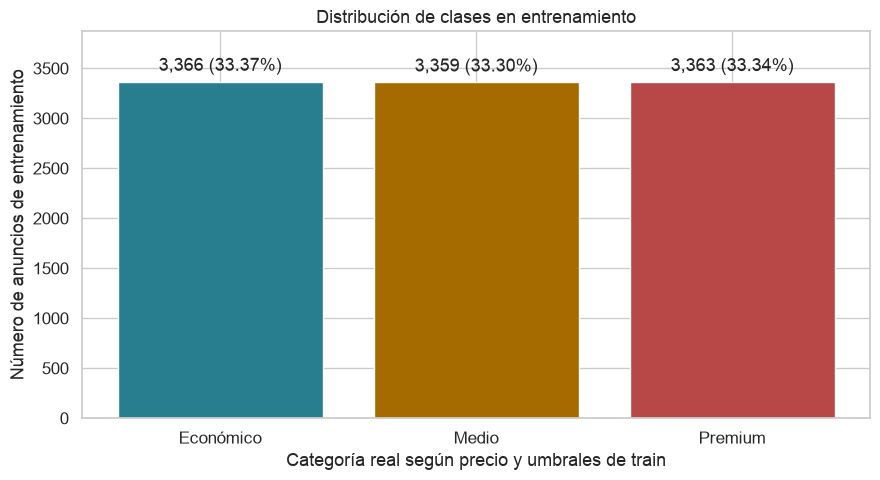

In [2]:
class_counts = y_train.value_counts(sort=False).reindex(LABELS)
class_distribution = class_counts.rename("anuncios_train").to_frame()
class_distribution["porcentaje_train"] = class_counts.div(len(y_train)).mul(100)
assert class_counts.sum() == len(eda_train)
display(class_distribution.round(2))
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(LABELS, class_counts, color=[PALETTE[label] for label in LABELS])
ax.bar_label(bars, labels=[f"{count:,} ({count / len(y_train):.2%})" for count in class_counts], padding=5)
ax.set(xlabel="Categoría real según precio y umbrales de train", ylabel="Número de anuncios de entrenamiento", title="Distribución de clases en entrenamiento")
ax.set_ylim(0, class_counts.max() * 1.15)
fig.tight_layout()
plt.show()

## 2. Variables seleccionadas y valores ausentes

Exploramos una selección explícita de variables numéricas de capacidad, amenities, condiciones de estancia, disponibilidad e historial. No es una selección final de features: el resto permanece en `X_train`.

Las medianas usan los valores disponibles de cada variable y categoría. Mostramos también el número de observaciones y el porcentaje ausente para no confundir diferencias de cobertura con diferencias entre alojamientos. Los valores vacíos se conservan; la imputación corresponde al Pipeline dentro de cada fold.

### Medianas por categoría real (sin imputar)

,accommodates,bedrooms,beds,bathrooms_count,amenities_count,minimum_nights,availability_365,number_of_reviews,review_scores_rating,reviews_per_month,host_tenure_years,days_since_last_review
price_segment,,,,,,,,,,,,
Económico,2.0,1.0,1.0,1.0,24.0,31.0,246.0,3.0,4.75,0.15,6.33,68.0
Medio,4.0,2.0,2.0,1.0,30.0,2.0,201.0,50.0,4.68,1.47,8.50,18.0
Premium,5.0,2.0,4.0,2.0,34.0,1.0,271.0,59.0,4.74,1.46,11.33,18.0


### Observaciones disponibles por variable y categoría real

,accommodates,bedrooms,beds,bathrooms_count,amenities_count,minimum_nights,availability_365,number_of_reviews,review_scores_rating,reviews_per_month,host_tenure_years,days_since_last_review
price_segment,,,,,,,,,,,,
Económico,3366,3365,3366,3364,3366,3173,3366,3366,2254,3366,3366,2254
Medio,3359,3359,3359,3357,3359,2664,3359,3359,2963,3359,3359,2963
Premium,3363,3363,3363,3362,3363,2783,3363,3363,2875,3363,3360,2875


### Porcentaje de datos ausentes por categoría real

,accommodates,bedrooms,beds,bathrooms_count,amenities_count,minimum_nights,availability_365,number_of_reviews,review_scores_rating,reviews_per_month,host_tenure_years,days_since_last_review
price_segment,,,,,,,,,,,,
Económico,0.0,0.03,0.0,0.06,0.0,5.73,0.0,0.0,33.04,0.0,0.00,33.04
Medio,0.0,0.00,0.0,0.06,0.0,20.69,0.0,0.0,11.79,0.0,0.00,11.79
Premium,0.0,0.00,0.0,0.03,0.0,17.25,0.0,0.0,14.51,0.0,0.09,14.51


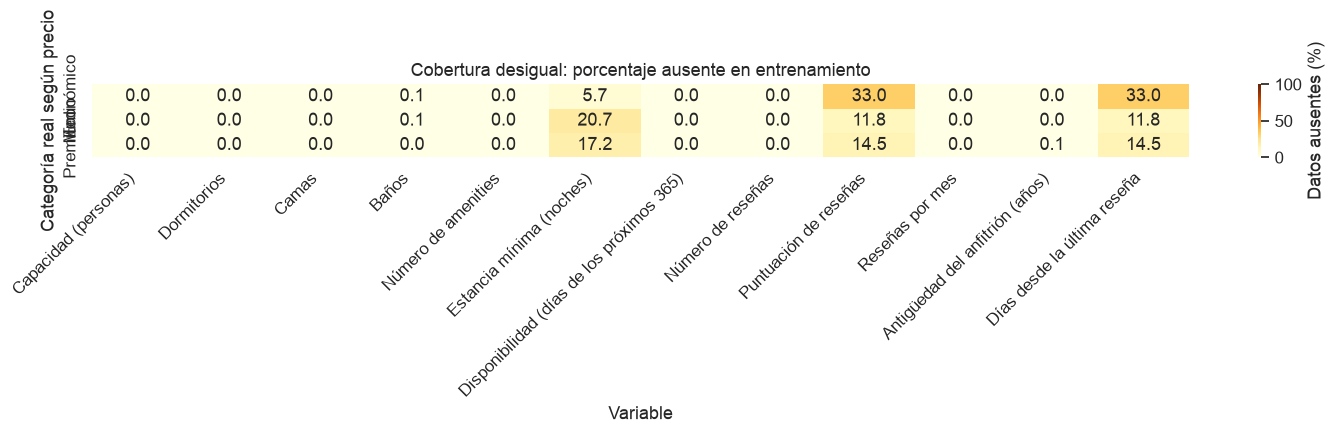

In [3]:
FEATURE_NAMES = {
    "accommodates": "Capacidad (personas)",
    "bedrooms": "Dormitorios",
    "beds": "Camas",
    "bathrooms_count": "Baños",
    "amenities_count": "Número de amenities",
    "minimum_nights": "Estancia mínima (noches)",
    "availability_365": "Disponibilidad (días de los próximos 365)",
    "number_of_reviews": "Número de reseñas",
    "review_scores_rating": "Puntuación de reseñas",
    "reviews_per_month": "Reseñas por mes",
    "host_tenure_years": "Antigüedad del anfitrión (años)",
    "days_since_last_review": "Días desde la última reseña",
}
FEATURES = list(FEATURE_NAMES)
assert set(FEATURES).issubset(X_train.columns), "Faltan variables del contrato: revisar el esquema"
assert all(pd.api.types.is_numeric_dtype(X_train[column]) for column in FEATURES)
assert not np.isinf(X_train[FEATURES].to_numpy(dtype=float, na_value=np.nan)).any()
grouped = eda_train.groupby(TARGET, observed=True)[FEATURES]
medians = grouped.median().reindex(LABELS)
valid_counts = grouped.count().reindex(LABELS)
missing_pct = 100 * (1 - valid_counts.div(class_counts, axis=0))
display(Markdown("### Medianas por categoría real (sin imputar)"))
display(medians.round(2))
display(Markdown("### Observaciones disponibles por variable y categoría real"))
display(valid_counts)
display(Markdown("### Porcentaje de datos ausentes por categoría real"))
display(missing_pct.round(2))
fig, ax = plt.subplots(figsize=(15, 4))
sns.heatmap(missing_pct.rename(columns=FEATURE_NAMES), annot=True, fmt=".1f", cmap="YlOrBr", vmin=0, vmax=100, cbar_kws={"label": "Datos ausentes (%)"}, ax=ax)
ax.set(xlabel="Variable", ylabel="Categoría real según precio", title="Cobertura desigual: porcentaje ausente en entrenamiento")
ax.tick_params(axis="x", rotation=45)
for tick in ax.get_xticklabels():
    tick.set_horizontalalignment("right")
fig.tight_layout()
plt.show()

## 3. Histogramas comparables por categoría real

Cada color representa una categoría real, no una predicción. Usamos intervalos comunes entre categorías para cada variable y normalizamos cada categoría por separado: la altura representa la proporción de sus observaciones disponibles que cae en el intervalo.

No eliminamos extremos ni rellenamos nulos. Para camas, estancia mínima y número de reseñas representamos `log(1 + valor)`, que comprime los valores grandes y admite cero. La transformación es solo visual: no cambia los datos de entrenamiento. El resto de ejes muestra las unidades originales.

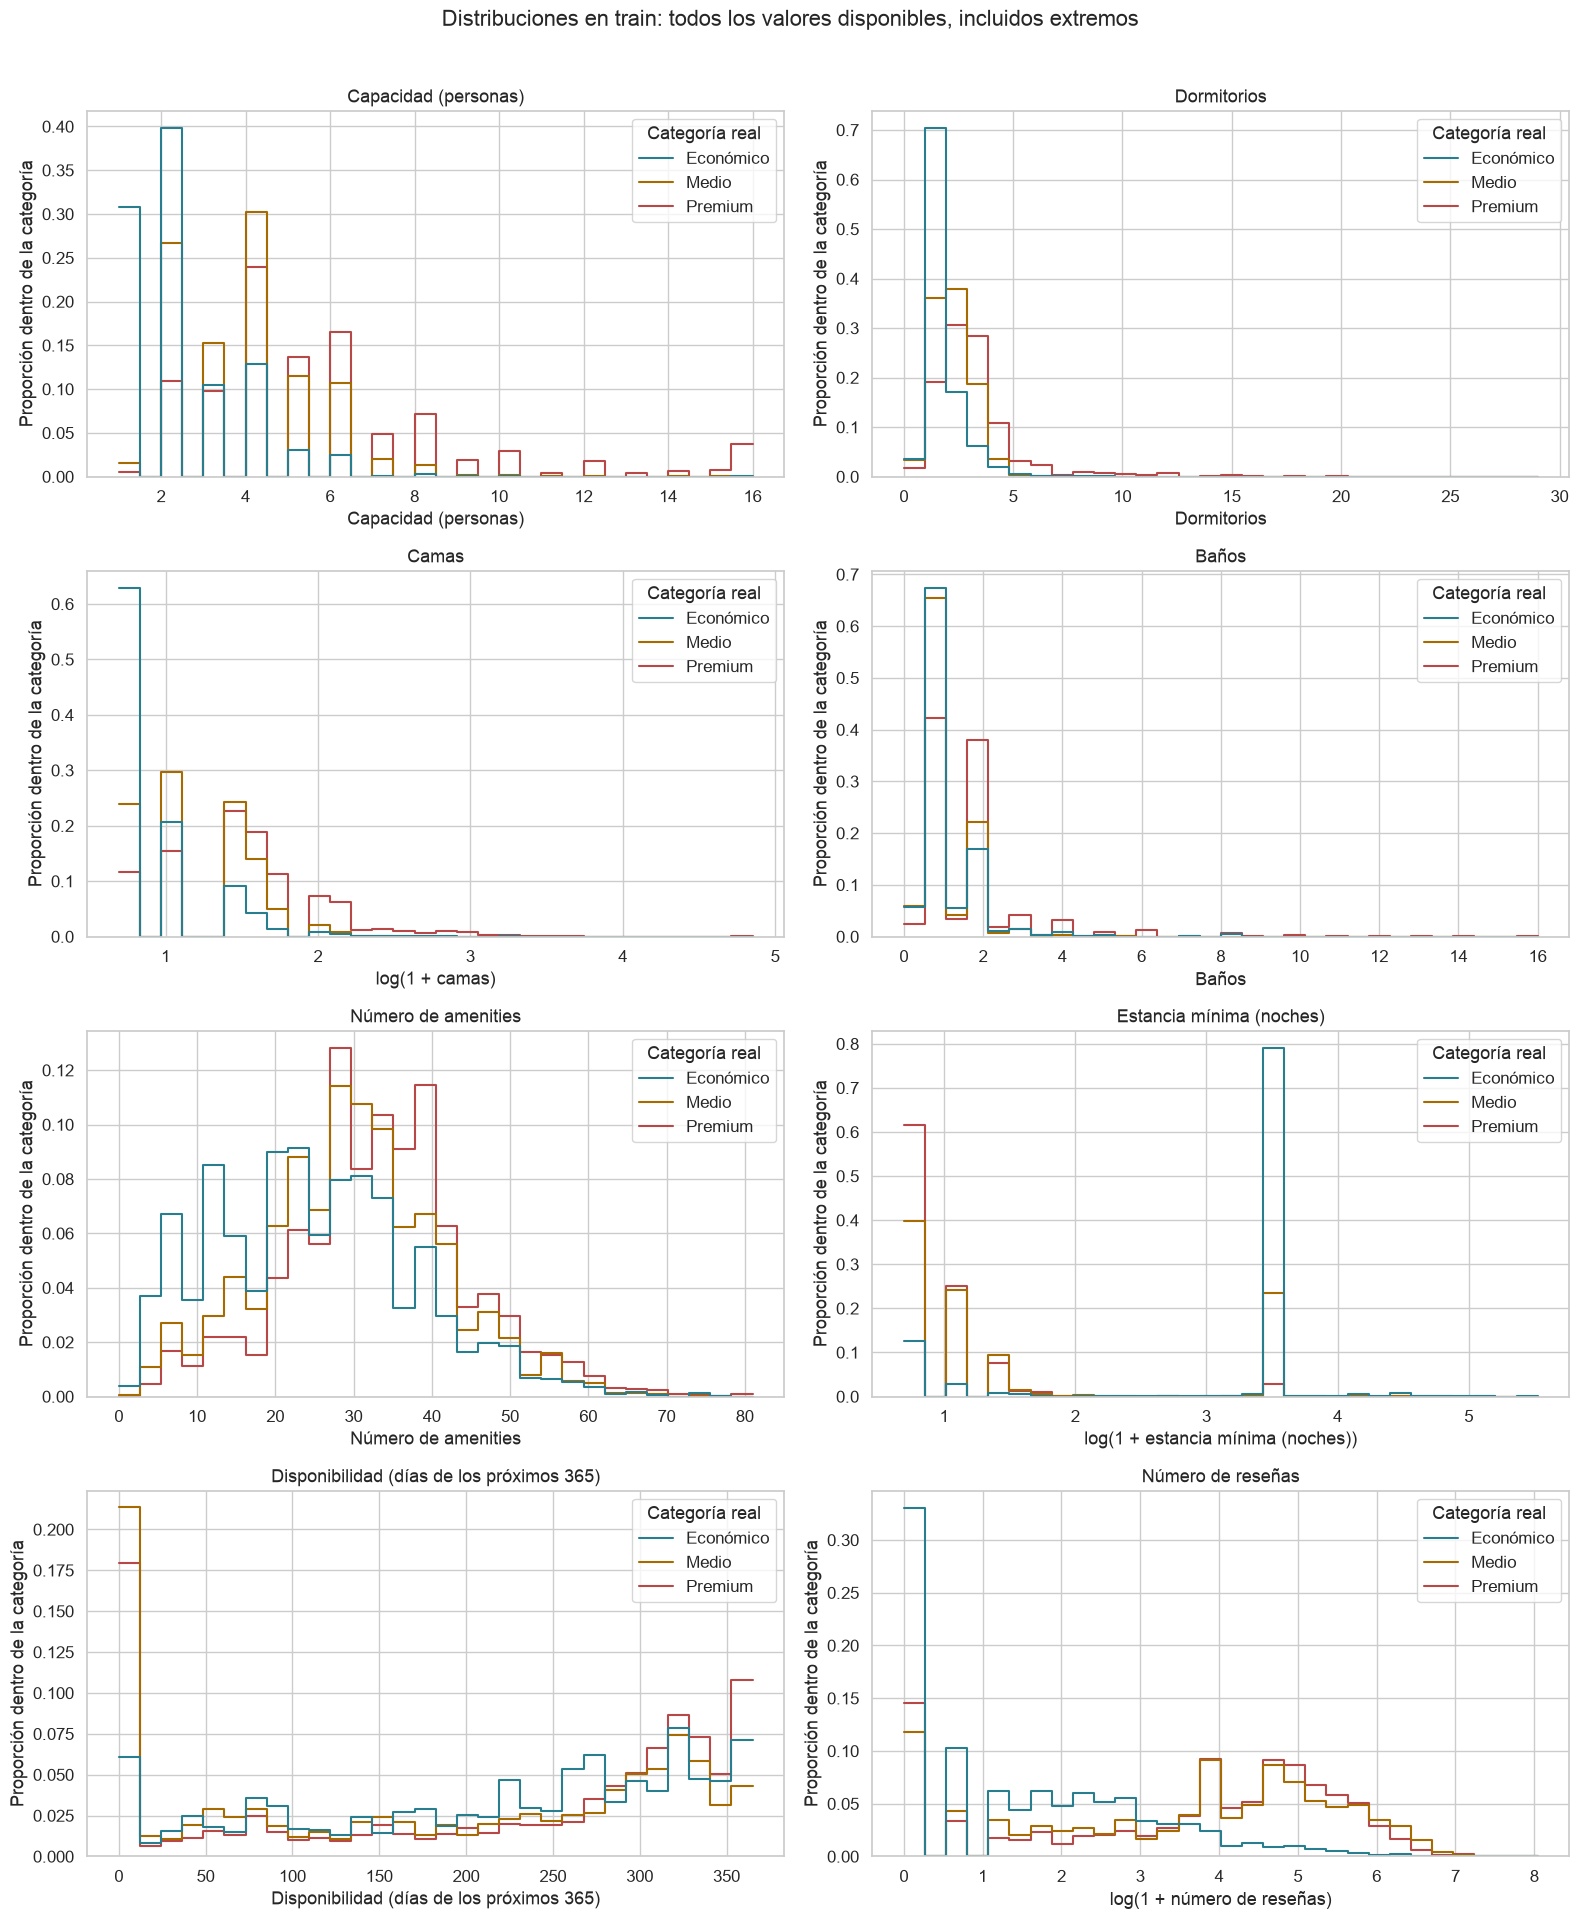

### Rango completo conservado (no implica validez de cada extremo)

,accommodates,bedrooms,beds,bathrooms_count,amenities_count,minimum_nights,availability_365,number_of_reviews
mínimo,1,0.0,1.0,0.0,0,1.0,0,0
máximo,16,29.0,127.0,16.0,81,250.0,365,3111


In [4]:
HIST_FEATURES = FEATURES[:8]
LOG_FEATURES = {"beds", "minimum_nights", "number_of_reviews"}
fig, axes = plt.subplots(4, 2, figsize=(16, 19))
for ax, column in zip(axes.flat, HIST_FEATURES):
    plot_data = eda_train[[column, TARGET]].dropna(subset=[column]).copy()
    if column in LOG_FEATURES:
        assert plot_data[column].ge(0).all()
        plot_data[column] = np.log1p(plot_data[column].astype(float))
    sns.histplot(data=plot_data, x=column, hue=TARGET, hue_order=LABELS, palette=PALETTE, bins=30, common_bins=True, stat="probability", common_norm=False, element="step", fill=False, ax=ax)
    label = FEATURE_NAMES[column]
    ax.set_title(label)
    ax.set_xlabel(f"log(1 + {label.lower()})" if column in LOG_FEATURES else label)
    ax.set_ylabel("Proporción dentro de la categoría")
    legend = ax.get_legend()
    if legend is not None:
        legend.set_title("Categoría real")
fig.suptitle("Distribuciones en train: todos los valores disponibles, incluidos extremos", y=1.01)
fig.tight_layout()
plt.show()
display(Markdown("### Rango completo conservado (no implica validez de cada extremo)"))
display(X_train[HIST_FEATURES].agg(["min", "max"]).rename(index={"min": "mínimo", "max": "máximo"}))

## 4. Correlación entre características numéricas

Usamos **Spearman**, que compara rangos y permite explorar asociaciones monótonas sin asumir relaciones lineales. Un valor próximo a +1 indica que ambas variables tienden a aumentar juntas; próximo a −1, que una tiende a disminuir cuando la otra aumenta. Un valor próximo a cero no descarta relaciones no monótonas.

La matriz contiene solo las 12 variables seleccionadas: no incluye precio ni convierte las categorías en números para tratarlas como una escala de distancias iguales. Cada coeficiente usa las filas disponibles para ese par (mínimo 30), sin imputación. **Correlación no demuestra causalidad, utilidad predictiva ni importancia del modelo.**

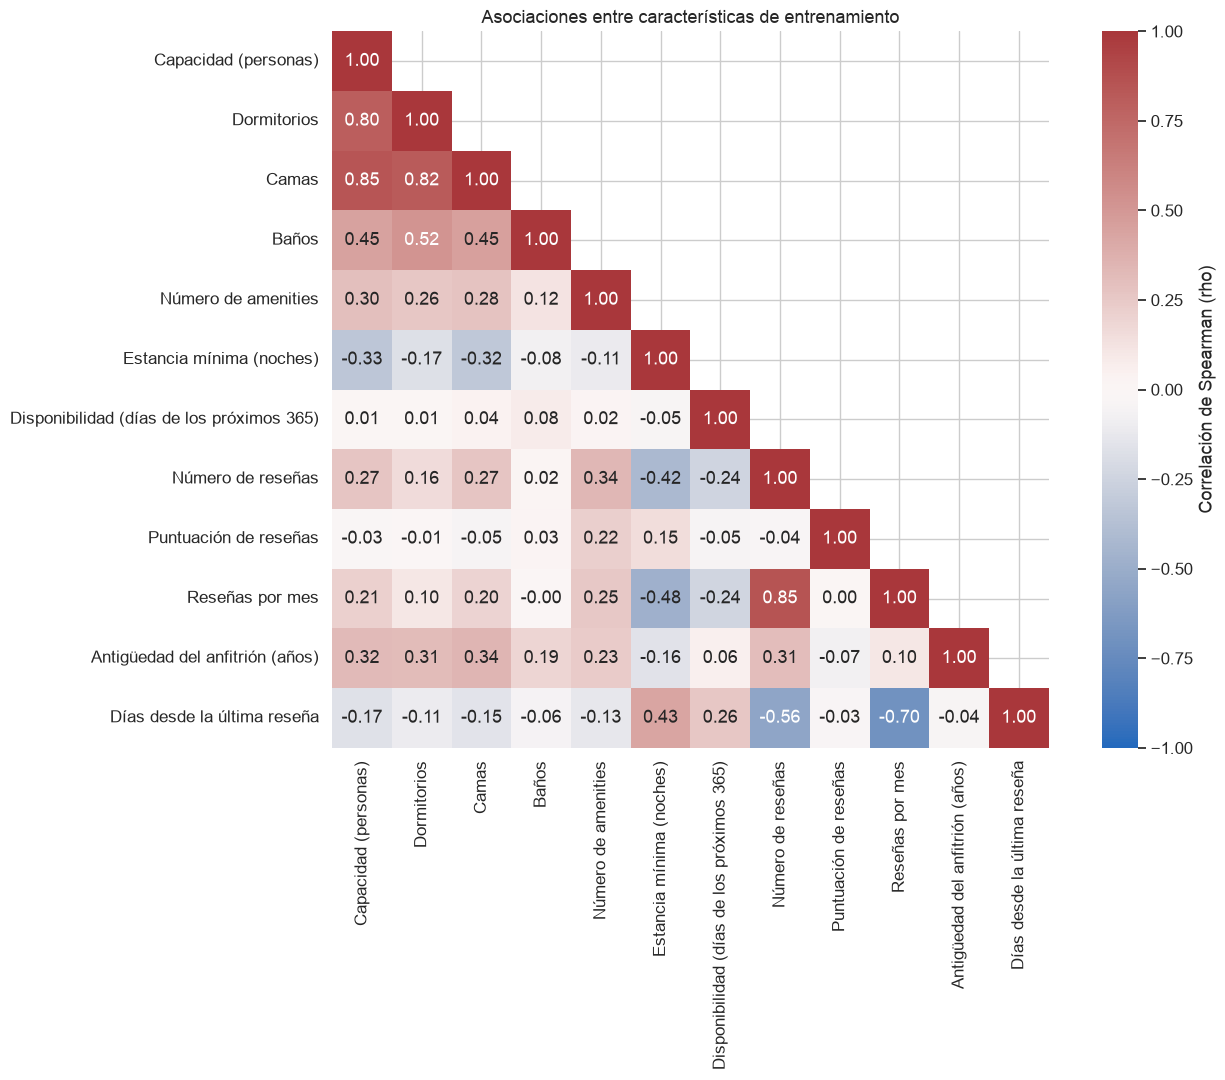

### Ocho pares con mayor correlación absoluta global, y su asociación dentro de cada categoría real

,variable_1,variable_2,rho_train,n_pareados_train,rho_Económico,n_Económico,rho_Medio,n_Medio,rho_Premium,n_Premium
0,number_of_reviews,reviews_per_month,0.852,10088,0.852,3366,0.759,3359,0.745,3363
1,accommodates,beds,0.847,10088,0.687,3366,0.785,3359,0.832,3363
2,bedrooms,beds,0.817,10087,0.683,3365,0.763,3359,0.822,3363
3,accommodates,bedrooms,0.803,10087,0.570,3365,0.777,3359,0.839,3363
4,reviews_per_month,days_since_last_review,-0.702,8092,-0.691,2254,-0.607,2963,-0.545,2875
5,number_of_reviews,days_since_last_review,-0.558,8092,-0.349,2254,-0.494,2963,-0.406,2875
6,bedrooms,bathrooms_count,0.517,10082,0.189,3363,0.452,3357,0.714,3362
7,minimum_nights,reviews_per_month,-0.484,8620,-0.294,3173,-0.486,2664,0.037,2783


In [5]:
correlations = X_train[FEATURES].corr(method="spearman", min_periods=30)
mask = np.triu(np.ones(correlations.shape, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(correlations.rename(index=FEATURE_NAMES, columns=FEATURE_NAMES), mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0, square=True, cbar_kws={"label": "Correlación de Spearman (rho)"}, ax=ax)
ax.set_title("Asociaciones entre características de entrenamiento")
fig.tight_layout()
plt.show()
pair_rows = []
for index, first in enumerate(FEATURES):
    for second in FEATURES[index + 1:]:
        pair_rows.append({
            "variable_1": first, "variable_2": second,
            "rho_train": correlations.loc[first, second],
            "n_pareados_train": len(X_train[[first, second]].dropna()),
        })
pairs = pd.DataFrame(pair_rows).dropna(subset=["rho_train"])
top_pairs = pairs.loc[pairs["rho_train"].abs().sort_values(ascending=False).index].head(8).copy()
for label in LABELS:
    subset = eda_train.loc[eda_train[TARGET] == label, FEATURES]
    within_class = subset.corr(method="spearman", min_periods=30)
    top_pairs[f"rho_{label}"] = [within_class.loc[row.variable_1, row.variable_2] for row in top_pairs.itertuples()]
    top_pairs[f"n_{label}"] = [len(subset[[row.variable_1, row.variable_2]].dropna()) for row in top_pairs.itertuples()]
display(Markdown("### Ocho pares con mayor correlación absoluta global, y su asociación dentro de cada categoría real"))
display(top_pairs.round(3).reset_index(drop=True))
assert correlations.stack().between(-1, 1).all()
assert (top_pairs["n_pareados_train"] >= 30).all()

## 5. Observaciones calculadas y límites

El siguiente resumen se genera con los resultados de esta ejecución, no con cifras copiadas de otra versión del dataset. Son descripciones de train, no pruebas de causalidad ni decisiones automáticas de selección.

In [6]:
def values_by_class(table, column, decimals=2, unit=""):
    return "; ".join(f"{label}: {table.loc[label, column]:.{decimals}f}{unit}" for label in LABELS)

capacity_beds = correlations.loc["accommodates", "beds"]
summary = [
    f"- **Equilibrio construido:** {len(y_train):,} anuncios de train repartidos por cuantiles. No inferimos de ello la composición natural del mercado.",
    f"- **Capacidad mediana (personas):** {values_by_class(medians, 'accommodates')}. **Amenities medianos:** {values_by_class(medians, 'amenities_count')}.",
    f"- **Estancia mínima mediana (noches, solo valores disponibles):** {values_by_class(medians, 'minimum_nights')}. Porcentaje ausente: {values_by_class(missing_pct, 'minimum_nights', unit=' %')}. Comparar estas condiciones además del precio por noche; no equivalen necesariamente a la misma duración de estancia.",
    f"- **Puntuación mediana de reseñas:** {values_by_class(medians, 'review_scores_rating')}. Porcentaje ausente: {values_by_class(missing_pct, 'review_scores_rating', unit=' %')}. No interpretar una categoría de precio como una valoración de calidad.",
    f"- **Capacidad y camas:** rho de Spearman = {capacity_beds:.3f}. Existe asociación en esta muestra; no justifica eliminar automáticamente una variable ni indica su importancia en un modelo.",
    f"- **Extremos a revisar:** máximo de dormitorios = {X_train['bedrooms'].max():g}; máximo de camas = {X_train['beds'].max():g}. Se conservan. Su validez requiere contrastar la fuente; no los declaramos errores solo por ser extremos.",
]
display(Markdown("\n\n".join(summary)))
assert len(eda_train) == len(X_train) == len(y_train)
pd.testing.assert_frame_equal(eda_train.drop(columns=[TARGET]), X_train)
print("Comprobaciones finales correctas: solo train, variables originales intactas y target alineado.")

- **Equilibrio construido:** 10,088 anuncios de train repartidos por cuantiles. No inferimos de ello la composición natural del mercado.

- **Capacidad mediana (personas):** Económico: 2.00; Medio: 4.00; Premium: 5.00. **Amenities medianos:** Económico: 24.00; Medio: 30.00; Premium: 34.00.

- **Estancia mínima mediana (noches, solo valores disponibles):** Económico: 31.00; Medio: 2.00; Premium: 1.00. Porcentaje ausente: Económico: 5.73 %; Medio: 20.69 %; Premium: 17.25 %. Comparar estas condiciones además del precio por noche; no equivalen necesariamente a la misma duración de estancia.

- **Puntuación mediana de reseñas:** Económico: 4.75; Medio: 4.68; Premium: 4.74. Porcentaje ausente: Económico: 33.04 %; Medio: 11.79 %; Premium: 14.51 %. No interpretar una categoría de precio como una valoración de calidad.

- **Capacidad y camas:** rho de Spearman = 0.847. Existe asociación en esta muestra; no justifica eliminar automáticamente una variable ni indica su importancia en un modelo.

- **Extremos a revisar:** máximo de dormitorios = 29; máximo de camas = 127. Se conservan. Su validez requiere contrastar la fuente; no los declaramos errores solo por ser extremos.

Comprobaciones finales correctas: solo train, variables originales intactas y target alineado.


### Interpretación y siguientes decisiones

- Los nulos y el historial disponible no se distribuyen igual entre categorías. Las medianas y correlaciones deben leerse junto con sus tamaños de muestra. Las variables de reseñas no estarán disponibles de la misma forma para un alojamiento nuevo.
- El split aleatorio no separa anfitriones ni periodos temporales. Este análisis no demuestra generalización a otros snapshots ni al mercado completo.
- Las asociaciones observadas sirven para formular hipótesis. No se reentrena, elimina ninguna variable, cambian umbrales ni consultan resultados de test en esta entrega.
- No hay acceso a red, base de datos ni escritura de datos o modelos en estas celdas. Guardar el notebook solo conserva código y resultados agregados. Los pasos para comprobar esta entrega están en `docs/pruebas_manuales.md`.

## 6. Correlación con la clase y selección de variables (solo train)

Tras la revisión del profesor, 71 columnas eran demasiadas. Criterios:

1. **Disponible al publicar el anuncio:** solo datos que el anfitrión conoce (sin historial de reseñas, ocupación ni cartera del anfitrión).
2. **Relación con la clase:** Spearman (numéricas) y V de Cramér (categóricas), calculadas solo con train.
3. **Sin redundancia:** de cada pareja con |Spearman| > 0,85 se queda una (p. ej. `minimum_nights` y no `minimum_minimum_nights`).
4. **Comprobación con CV**, al final de esta sección.

Correlación baja no siempre significa inútil: `latitude`/`longitude` tienen ~0, pero su efecto no es lineal (zonas caras) y quitarlas empeora el CV. La lista final está en `MODEL_FEATURES` (`src/cleaning.py`) y el detalle de cada simplificación en `docs/decisiones.md`.

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from src.cleaning import (
    MODEL_EXCLUDED_COLUMNS, MODEL_FEATURES,
    clean_listings, engineer_features,
)
from src.preprocessing import RAW_DATA_PATH, load_train_test

# Solo TRAIN: la selección de columnas es una decisión y no puede mirar test.
X_train, _, y_train, _ = load_train_test()
featured = engineer_features(clean_listings(pd.read_csv(RAW_DATA_PATH)))
candidates = featured.loc[X_train.index].drop(columns=list(MODEL_EXCLUDED_COLUMNS), errors="ignore")
y_ord = y_train.map({"Económico": 0, "Medio": 1, "Premium": 2}).astype(float)

# 1) Numéricas: correlación de Spearman con la clase (orden Económico < Medio < Premium)
numeric = candidates.select_dtypes("number")
spearman = numeric.apply(lambda col: col.corr(y_ord, method="spearman"))

# 2) Categóricas: V de Cramér con la clase
def cramers_v(col):
    table = pd.crosstab(col, y_train)
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

cramer = candidates.select_dtypes(exclude="number").apply(cramers_v)

summary = pd.DataFrame({"relacion_con_clase": pd.concat([spearman.abs(), cramer])})
summary["metodo"] = ["Spearman"] * len(spearman) + ["Cramér V"] * len(cramer)
summary["en_el_modelo"] = summary.index.isin(MODEL_FEATURES)
summary = summary.sort_values("relacion_con_clase", ascending=False).round(2)
display(summary)

# 3) Redundancia entre las features elegidas (|Spearman| > 0,85)
chosen = numeric[[c for c in MODEL_FEATURES if c in numeric]].corr(method="spearman").abs()
pairs = [(a, b, round(chosen.loc[a, b], 2)) for i, a in enumerate(chosen) for b in chosen.columns[i + 1:] if chosen.loc[a, b] > 0.85]
print("Parejas redundantes entre las features elegidas:", pairs or "ninguna")

,relacion_con_clase,metodo,en_el_modelo
minimum_nights,0.62,Spearman,True
minimum_minimum_nights,0.62,Spearman,False
accommodates,0.59,Spearman,True
maximum_minimum_nights,0.58,Spearman,False
minimum_nights_avg_ntm,0.57,Spearman,False
...,...,...,...
latitude,0.01,Spearman,True
review_scores_rating,0.01,Spearman,False
has_clothes_dryer,0.00,Spearman,False
review_scores_accuracy,0.00,Spearman,False


Parejas redundantes entre las features elegidas: ninguna


In [8]:
# Comprobación con CV (solo train): todas las candidatas vs. las variables elegidas
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from src.preprocessing import build_preprocessor

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
feature_sets = {
    f"Todas las candidatas ({candidates.shape[1]})": candidates,
    f"Elegidas: MODEL_FEATURES ({len(MODEL_FEATURES)})": X_train,
}
rows = []
for set_name, data in feature_sets.items():
    for model_name, model in [
        ("LogReg", LogisticRegression(max_iter=3000)),
        ("Boosting", HistGradientBoostingClassifier(random_state=42)),
    ]:
        pipe = Pipeline([("prep", build_preprocessor()), ("model", model)])
        scores = cross_validate(pipe, data, y_train, cv=cv, scoring="f1_macro", return_train_score=True)
        rows.append({
            "variables": set_name, "modelo": model_name,
            "f1_train": scores["train_score"].mean(), "f1_validacion": scores["test_score"].mean(),
        })
display(pd.DataFrame(rows).round(3))

,variables,modelo,f1_train,f1_validacion
0,Todas las candidatas (71),LogReg,0.782,0.765
1,Todas las candidatas (71),Boosting,0.991,0.812
2,Elegidas: MODEL_FEATURES (23),LogReg,0.740,0.729
3,Elegidas: MODEL_FEATURES (23),Boosting,0.910,0.773


### 6.1 Ablación reproducible (solo train)

Para que cada simplificación sea verificable, retiramos los grupos de columnas **paso a paso y de forma acumulativa**, con los mismos 5 folds, el mismo preprocesamiento y los mismos modelos por defecto. Se muestran las columnas exactas de cada paso, la media, la desviación y los resultados por fold.

- Los pasos 1–3 y 6 se deciden por la **regla del producto** (anuncios nuevos), no por su aportación.
- Los pasos 5, 7 y 8 son simplificaciones con **pérdidas pequeñas y aceptadas**.
- Son resultados **diagnósticos**: elegimos variables mirando esta misma validación, así que no sustituyen la evaluación final en test.

In [9]:
# Ablación reproducible (solo train): de las candidatas a MODEL_FEATURES, paso a paso.
# Los pasos son ACUMULATIVOS: cada uno parte del conjunto del paso anterior.
# Mismos 5 folds, mismo preprocesamiento y modelos por defecto en todos los pasos.
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from src.preprocessing import build_preprocessor

cols = list(candidates.columns)
review_cols = [c for c in cols if "review" in c]
availability_cols = [c for c in cols if c.startswith("availability") or c in ("has_availability", "estimated_occupancy_l365d")]
host_history_cols = [c for c in cols if "listings_count" in c or c.startswith("hosts_time_as_") or c in ("host_tenure_years", "host_has_profile_pic", "host_identity_verified")]
nights_variants = [c for c in cols if c.endswith(("_nights", "_nights_avg_ntm")) and c not in ("minimum_nights", "maximum_nights")]

steps = [
    ("0 · Todas las candidatas", []),
    ("1 · Sin reseñas", review_cols),
    ("2 · Sin disponibilidad/ocupación", availability_cols),
    ("3 · Sin historial del anfitrión", host_history_cols),
    ("4 · Sin indicadores de limpieza", ["beds_was_missing", "minimum_nights_was_missing"]),
    ("5 · Sin variantes de noches", nights_variants),
    ("6 · Sin host_is_superhost", ["host_is_superhost"]),
    ("7 · Sin amenities_count", ["amenities_count"]),
    ("8 · Sin has_washer, has_clothes_dryer, maximum_nights", ["has_washer", "has_clothes_dryer", "maximum_nights"]),
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models = {
    "LogReg": lambda: LogisticRegression(max_iter=3000),
    "Boosting": lambda: HistGradientBoostingClassifier(random_state=42),
}

def evaluate(columns):
    row = {"n_variables": len(columns)}
    for name, make in models.items():
        pipe = Pipeline([("prep", build_preprocessor()), ("model", make())])
        scores = cross_validate(pipe, candidates[columns], y_train, cv=cv, scoring="f1_macro", return_train_score=True)
        row[f"{name}_val_media"] = scores["test_score"].mean()
        row[f"{name}_val_std"] = scores["test_score"].std()
        row[f"{name}_train_media"] = scores["train_score"].mean()
        row[f"{name}_val_por_fold"] = np.round(scores["test_score"], 3).tolist()
    return row

current = cols.copy()
rows, removed_by_step = [], {}
for step, to_remove in steps:
    current = [c for c in current if c not in to_remove]
    removed_by_step[step] = to_remove
    rows.append({"paso": step, **evaluate(current)})

assert set(current) == set(MODEL_FEATURES), "El último paso debe coincidir con MODEL_FEATURES"

# Comparaciones laterales, partiendo de las 23 finales
side = {
    "23 + has_washer, has_clothes_dryer, maximum_nights (26)": list(MODEL_FEATURES) + ["has_washer", "has_clothes_dryer", "maximum_nights"],
    "23 sin latitude/longitude (21)": [c for c in MODEL_FEATURES if c not in ("latitude", "longitude")],
}
for name, columns in side.items():
    rows.append({"paso": f"Comparación · {name}", **evaluate(columns)})

ablation = pd.DataFrame(rows).set_index("paso")
display(ablation.drop(columns=[c for c in ablation if c.endswith("por_fold")]).round(3))
display(ablation[[c for c in ablation if c.endswith("por_fold")]])
for step, removed in removed_by_step.items():
    if removed:
        print(f"{step}: {removed}")

,n_variables,LogReg_val_media,LogReg_val_std,LogReg_train_media,Boosting_val_media,Boosting_val_std,Boosting_train_media
paso,,,,,,,
0 · Todas las candidatas,71,0.765,0.007,0.782,0.812,0.004,0.991
1 · Sin reseñas,55,0.758,0.003,0.775,0.817,0.006,0.978
2 · Sin disponibilidad/ocupación,48,0.746,0.004,0.761,0.807,0.005,0.959
3 · Sin historial del anfitrión,36,0.740,0.008,0.756,0.796,0.008,0.949
4 · Sin indicadores de limpieza,34,0.743,0.006,0.757,0.797,0.004,0.948
5 · Sin variantes de noches,28,0.730,0.007,0.743,0.783,0.003,0.932
6 · Sin host_is_superhost,27,0.729,0.007,0.743,0.779,0.004,0.931
7 · Sin amenities_count,26,0.730,0.007,0.741,0.776,0.007,0.922
"8 · Sin has_washer, has_clothes_dryer, maximum_nights",23,0.729,0.006,0.740,0.773,0.006,0.910


,LogReg_val_por_fold,Boosting_val_por_fold
paso,,
0 · Todas las candidatas,"[0.763, 0.774, 0.773, 0.76, 0.756]","[0.809, 0.815, 0.819, 0.807, 0.811]"
1 · Sin reseñas,"[0.758, 0.763, 0.759, 0.755, 0.756]","[0.812, 0.819, 0.822, 0.808, 0.822]"
2 · Sin disponibilidad/ocupación,"[0.748, 0.753, 0.746, 0.742, 0.743]","[0.802, 0.808, 0.815, 0.801, 0.811]"
3 · Sin historial del anfitrión,"[0.732, 0.749, 0.746, 0.742, 0.729]","[0.788, 0.805, 0.804, 0.787, 0.799]"
4 · Sin indicadores de limpieza,"[0.739, 0.75, 0.745, 0.747, 0.733]","[0.791, 0.798, 0.802, 0.795, 0.798]"
5 · Sin variantes de noches,"[0.718, 0.734, 0.737, 0.735, 0.726]","[0.782, 0.786, 0.784, 0.778, 0.786]"
6 · Sin host_is_superhost,"[0.717, 0.732, 0.737, 0.734, 0.727]","[0.773, 0.781, 0.782, 0.775, 0.783]"
7 · Sin amenities_count,"[0.718, 0.735, 0.738, 0.732, 0.726]","[0.77, 0.773, 0.789, 0.77, 0.78]"
"8 · Sin has_washer, has_clothes_dryer, maximum_nights","[0.721, 0.729, 0.738, 0.731, 0.723]","[0.77, 0.769, 0.784, 0.769, 0.775]"


1 · Sin reseñas: ['number_of_reviews', 'number_of_reviews_ltm', 'number_of_reviews_l30d', 'number_of_reviews_ly', 'review_scores_rating', 'review_scores_accuracy', 'review_scores_cleanliness', 'review_scores_checkin', 'review_scores_communication', 'review_scores_location', 'review_scores_value', 'reviews_per_month', 'has_reviews', 'days_since_last_review', 'days_since_first_review', 'review_span_days']
2 · Sin disponibilidad/ocupación: ['has_availability', 'availability_30', 'availability_60', 'availability_90', 'availability_365', 'availability_eoy', 'estimated_occupancy_l365d']
3 · Sin historial del anfitrión: ['hosts_time_as_user_years', 'hosts_time_as_user_months', 'hosts_time_as_host_years', 'hosts_time_as_host_months', 'host_listings_count', 'host_has_profile_pic', 'host_identity_verified', 'calculated_host_listings_count', 'calculated_host_listings_count_entire_homes', 'calculated_host_listings_count_private_rooms', 'calculated_host_listings_count_shared_rooms', 'host_tenure_ye